# $\log 2$: historical constructions

Exact rational approximants, sampled up to index 500.
$\delta_N=-1-\log|\alpha-p_N/q_N|/\log q_N$ and
$D_N=-\log_{10}|\alpha-p_N/q_N|$, with reduced $p_N/q_N$.
Published results and finite-depth measurements are distinct; source-index exceptions are stated below.

In [ ]:
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 python-flint==0.9.0 matplotlib==3.11.2

## Setup

In [1]:
import sys
import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from IPython.display import Markdown, display
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq
from cmfs import (
    huttner_logs, huttner_logs_seeds, integer_staircase_states,
    rhin_log2, rhin_log2_full, rhin_log2_path,
    rhin_log2_seeds,
)

sys.set_int_max_str_digits(0)
DEPTHS = list(range(10, 501, 10))
results, accuracy = {}, {}
x0, x1, x2, y0, y1 = sp.symbols('x0 x1 x2 y0 y1')
target = lambda: arb(2).log()


def measure(approximant, target):
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(4 * q.bit_length() + 256):
        error = abs(target() - arb(p) / q)
        assert error > 0 and q > 1
        value = -1 - error.log() / arb(q).log()
        assert value.is_finite() and value.rad() < arb("1e-18")
        return float(value.mid()), float((-error.log() / arb(10).log()).mid())

## 1. Alladi–Robinson (1980)

[Zudilin (2004), §1](https://arxiv.org/html/math/0404523).

**CMF:** ${}_2F_1(-1)$, rank 2. **Start:** $(1,1;2)$. **Direction:** $(1,1;2)$.
**Readout:** $W_{10}/[2(W_{10}-W_{00})]$. N is the source index.

In [5]:
cmf = pFq(2, 1, -1)
start = {x0: 1, x1: 1, y0: 2}
trajectory = {x0: 1, x1: 1, y0: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[1, 0] / (2 * (W[1, 0] - W[0, 0])) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Alladi–Robinson (1980)'] = (DEPTHS, deltas)
accuracy['Alladi–Robinson (1980)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.297989402316


## 2. Chudnovsky benchmark (1980s; Rhin reconstruction 1987)

[Rhin (1987), pp. 159–160](https://doi.org/10.1007/978-1-4757-4267-1_11).

**CMF:** rank-4 moments of $[t(1-t)]^{e_1}(6t^2-5t+1)^{e_2}(1+t)^{-b}$.
**Start:** $(0,0,1)$. **Direction:** $(9,1,10)$. Source index N uses N/10 steps.
**Readout:** $-(CW)_0/(QW)_0$ from the logarithmic coefficient rows.
Rhin describes the attribution to Chudnovsky as probable.

In [7]:
e1, e2, b = sp.symbols('e1 e2 b')
cmf = rhin_log2()
start = {e1: 0, e2: 0, b: 1}
trajectory = {e1: 9, e2: 1, b: 10}
walks = cmf.walk(trajectory, [N // 10 for N in DEPTHS], start)
C = Matrix([[0, 1, -sp.Rational(1, 2), sp.Rational(5, 6)]])
R = Matrix([[1, -1, 1, -1]])
approximants = [-(C * W)[0] / (R * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Chudnovsky benchmark (Rhin reconstruction)'] = (DEPTHS, deltas)
accuracy['Chudnovsky benchmark (Rhin reconstruction)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.335555285288


## 3. Rukhadze (1987)

[Local manuscript](../overleaf_paper/New_directions_in_irrationality/main.tex).

**CMF:** dual ${}_2F_1(-1)$, rank 2. **Start:** $(1,1;2)$. **Direction:** $(7,6;14)$.
**Readout:** $W_{00}/[2(W_{10}+W_{00})]$. N is the walk length.

In [9]:
cmf = pFq(2, 1, -1).dual()
start = {x0: 1, x1: 1, y0: 2}
trajectory = {x0: 7, x1: 6, y0: 14}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [W[0, 0] / (2 * W[1, 0] + 2 * W[0, 0]) for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rukhadze (1987)'] = (DEPTHS, deltas)
accuracy['Rukhadze (1987)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.347724894141


## 4. Rhin (1987)

[Rhin (1987), Appendix 1](https://doi.org/10.1007/978-1-4757-4267-1_11).

**CMF:** rank-14 moments with Rhin's six polynomial factors, evaluated at integer points.
**Start:** $(0,0,0,0,0,0,1)$. **Path:** $(\lfloor\sigma_1N\rfloor,\ldots,\lfloor\sigma_6N\rfloor,N+1)$,
where $\sigma=(.84943,.02401,.09100,.02068,.01130,.00179)$.
**Readout:** $-C_0/Q_0$ from $S=C+Q\log2$. N is the source index.

In [11]:
cmf = rhin_log2_full()
start = rhin_log2_path(0)
trajectory = rhin_log2_path
seeds = rhin_log2_seeds()
walks = integer_staircase_states(cmf, start, trajectory, DEPTHS, seeds)
approximants = [-W[0, 0] / W[1, 0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Rhin (1987)'] = (DEPTHS, deltas)
accuracy['Rhin (1987)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.335582529347


## 5. Huttner (2003): $\log 2$ from the simultaneous construction

[Corollary 3.1(4), pp. 146–147](https://www.jstage.jst.go.jp/article/kyushujm/57/1/57_1_129/_pdf).

**CMF:** rank-3 moments of $(z-1)^u(z-2/3)^v(z-1/2)^w z^{-m}$.
**Start/direction:** $(2,2,2,3)$. Source index N uses N−1 steps.
**Readout:** $(PW)_0/(QW)_0$ from the source's simultaneous logarithmic coefficient rows.

In [13]:
u, v, w, m = sp.symbols('u v w m')
cmf = huttner_logs()
start = {u: 2, v: 2, w: 2, m: 3}
trajectory = {u: 2, v: 2, w: 2, m: 3}
P, Q = huttner_logs_seeds(2)
walks = cmf.walk(trajectory, [N - 1 for N in DEPTHS], start)
approximants = [(P * W)[0] / (Q * W)[0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Huttner (2003), simultaneous'] = (DEPTHS, deltas)
accuracy['Huttner (2003), simultaneous'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.231222633922


## 6. Marcovecchio (2009)

[Acta Arith. **139** (2009)](https://doi.org/10.4064/aa139-2-5).

**CMF:** ${}_3F_2(1/2)$, rank 3. **Start:** $(1,1,1;2,1)$. **Direction:** $(7,5,6;2,1)$.
**Readout:** $(W_{10}-W_{00})/W_{10}$. N is the walk length.

In [15]:
cmf = pFq(3, 2, sp.Rational(1, 2))
start = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 1}
trajectory = {x0: 7, x1: 5, x2: 6, y0: 2, y1: 1}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(W[1, 0] - W[0, 0]) / W[1, 0] for W in walks]

measurements = [measure(r, target) for r in approximants]
deltas = [value[0] for value in measurements]
results['Marcovecchio (2009)'] = (DEPTHS, deltas)
accuracy['Marcovecchio (2009)'] = [value[1] for value in measurements]
print(f"delta at N = {DEPTHS[-1]}: {deltas[-1]:.12f}")

delta at N = 500: 0.395480934234


## Comparison

Only completed runs are shown. N follows each example’s stated index convention.

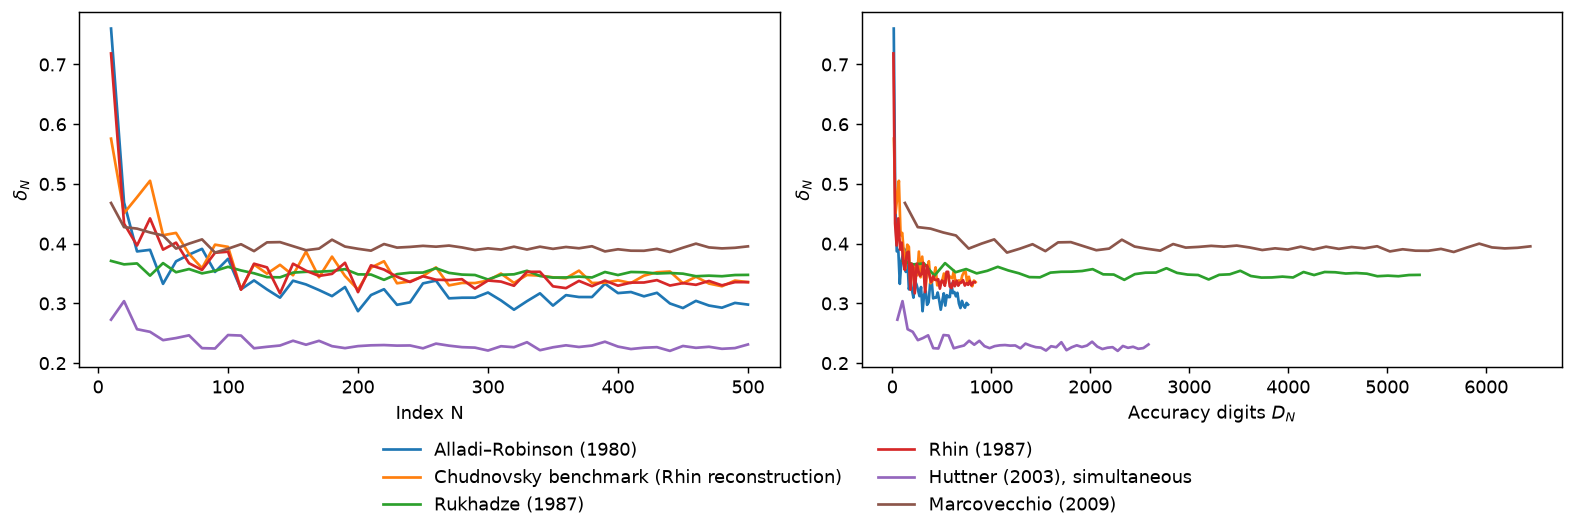

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name, (depths, deltas) in results.items():
    axes[0].plot(depths, deltas, label=name)
    axes[1].plot(accuracy[name], deltas)
axes[0].set(xlabel="Index N", ylabel=r"$\delta_N$")
axes[1].set(xlabel=r"Accuracy digits $D_N$", ylabel=r"$\delta_N$")
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=2, frameon=False)
plt.show()

## Historical overview

Only implemented CMF recoveries are listed. The measured column states the actual final index.

In [19]:
bounds = {
    'Alladi–Robinson (1980)': '$4.6221$',
    'Chudnovsky benchmark (Rhin reconstruction)': '$4.1344$',
    'Rukhadze (1987)': '$3.89139978$',
    'Rhin (1987)': '$4.0765$',
    'Huttner (2003), simultaneous': '$11.1017577\\ldots$',
    'Marcovecchio (2009)': '$3.57455391$',
}
rows = ["| Construction | Published result | Measured delta |", "|:--|:--|:--|"]
for name, bound in bounds.items():
    if name in results:
        depths, deltas = results[name]
        value = f"{deltas[-1]:.12f} (N = {depths[-1]})"
    else:
        value = "Not computed"
    rows.append(f"| {name} | {bound} | {value} |")
display(Markdown("\n".join(rows)))

| Construction | Published result | Measured delta |
|:--|:--|:--|
| Alladi–Robinson (1980) | $4.6221$ | 0.297989402316 (N = 500) |
| Chudnovsky benchmark (Rhin reconstruction) | $4.1344$ | 0.335555285288 (N = 500) |
| Rukhadze (1987) | $3.89139978$ | 0.347724894141 (N = 500) |
| Rhin (1987) | $4.0765$ | 0.335582529347 (N = 500) |
| Huttner (2003), simultaneous | $11.1017577\ldots$ | 0.231222633922 (N = 500) |
| Marcovecchio (2009) | $3.57455391$ | 0.395480934234 (N = 500) |